# Detección de objetos con Faster R-CNN
Pipeline completo e independiente de `src/`. Procesa solo `image.png` e `image2.png`.

**En Kaggle:** importa este notebook, adjunta un dataset con las dos imágenes de `imgs/`,
activa Internet para descargar los pesos y ejecuta todas las celdas. Usa CPU.
Las salidas se guardan en `/kaggle/working/resultados/`. En local, usa `imgs/` y `resultados/`.
PyTorch, Torchvision, Pillow e IPython deben estar instalados en el kernel.

Faster R-CNN propone regiones y después las clasifica y ajusta. YOLO predice cajas y clases
sin una etapa de propuestas. Aquí se ejecuta únicamente Faster R-CNN; no se mide YOLO.


## 01 Preparar herramientas y localizar las dos imágenes


In [1]:
from pathlib import Path
import csv
import platform
import time

import torch
import torchvision
from PIL import Image, ImageOps
from IPython.display import HTML, display
from torchvision.models.detection import (
    FasterRCNN_MobileNet_V3_Large_FPN_Weights,
    fasterrcnn_mobilenet_v3_large_fpn,
)
from torchvision.transforms.functional import pil_to_tensor, to_pil_image
from torchvision.utils import draw_bounding_boxes

entrada = Path('/kaggle/input') if Path('/kaggle/input').is_dir() else Path('imgs')
salida = Path('/kaggle/working/resultados') if Path('/kaggle/working').is_dir() else Path('resultados')
rutas = []
for nombre in ('image.png', 'image2.png'):
    coincidencias = sorted(entrada.rglob(nombre))
    if len(coincidencias) != 1:
        raise FileNotFoundError(f'Se necesita exactamente una {nombre} en {entrada}; encontradas: {len(coincidencias)}')
    rutas.append(coincidencias[0])
salida.mkdir(exist_ok=True)
print(f'Python {platform.python_version()} | PyTorch {torch.__version__} | Torchvision {torchvision.__version__}')
print(f'Dispositivo: CPU | Hilos: {torch.get_num_threads()}')
print('Imágenes:', [str(ruta) for ruta in rutas])


Python 3.13.12 | PyTorch 2.9.0+cpu | Torchvision 0.24.0+cpu
Dispositivo: CPU | Hilos: 8
Imágenes: ['imgs/image.png', 'imgs/image2.png']


## 02 Cargar Faster R-CNN
MobileNetV3 con FPN y pesos COCO V1. Modo evaluación, sin entrenamiento y umbral de confianza de 0.5.
La carga y la descarga del modelo quedan fuera del tiempo de inferencia.


In [2]:
pesos = FasterRCNN_MobileNet_V3_Large_FPN_Weights.COCO_V1
modelo = fasterrcnn_mobilenet_v3_large_fpn(weights=pesos).eval()


## 03 Detectar objetos y guardar evidencia
Se mide una inferencia por imagen con `time.perf_counter()` y se convierte a milisegundos.
Se excluyen lectura, preprocesamiento, filtrado y dibujo. No se realiza calentamiento:
la primera inferencia puede incluir inicialización interna. El conteo corresponde a
predicciones con confianza ≥ 0.5, no a objetos confirmados manualmente.


image.png: 24 detecciones | 10091.63 ms
person 100%, dog 100%, bus 100%, person 100%, traffic light 99%, person 98%, person 98%, person 98%, person 97%, person 97%, person 97%, car 91%, car 89%, traffic light 84%, handbag 84%, bus 84%, person 83%, person 71%, person 70%, person 69%, handbag 67%, car 62%, bus 58%, person 52%


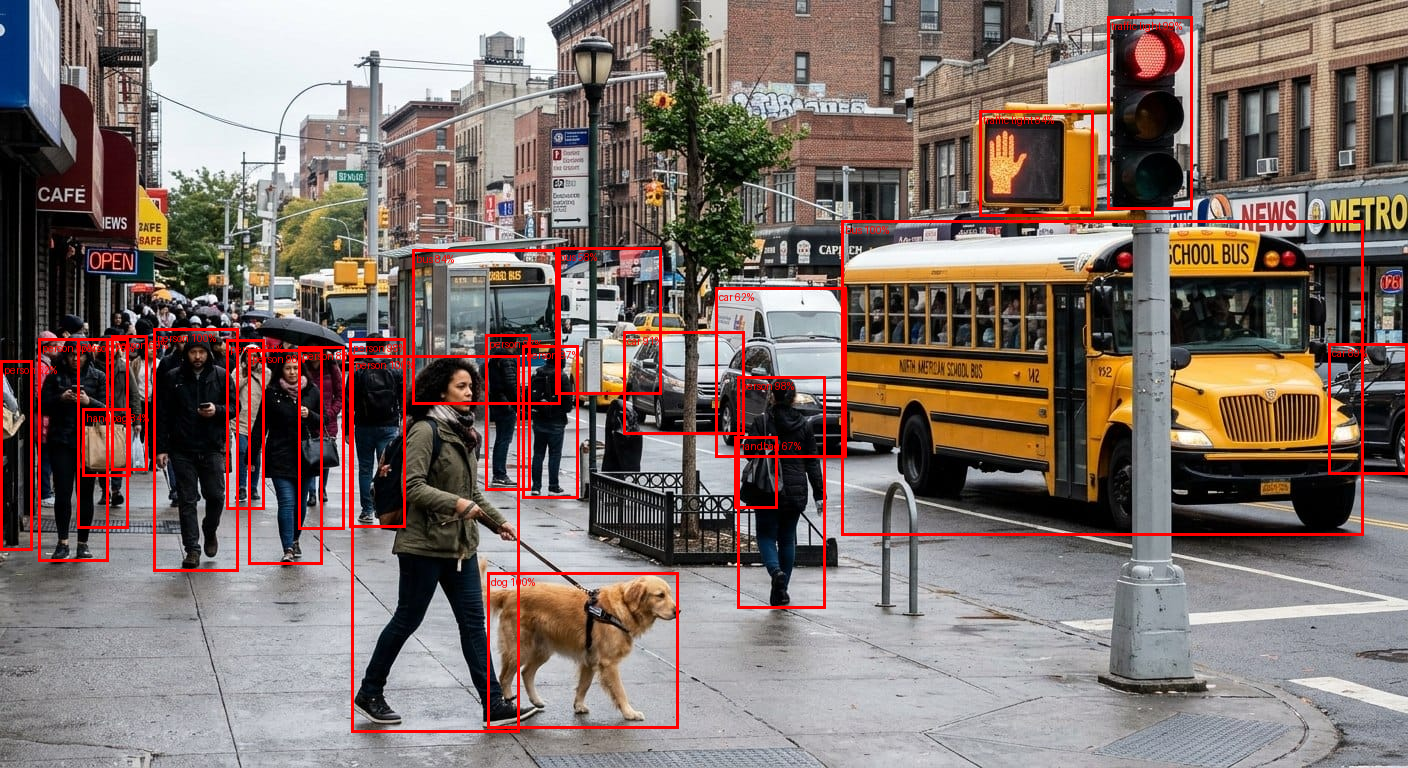

image2.png: 9 detecciones | 1000.75 ms
car 94%, car 92%, car 92%, car 90%, car 81%, car 80%, car 73%, car 70%, car 54%


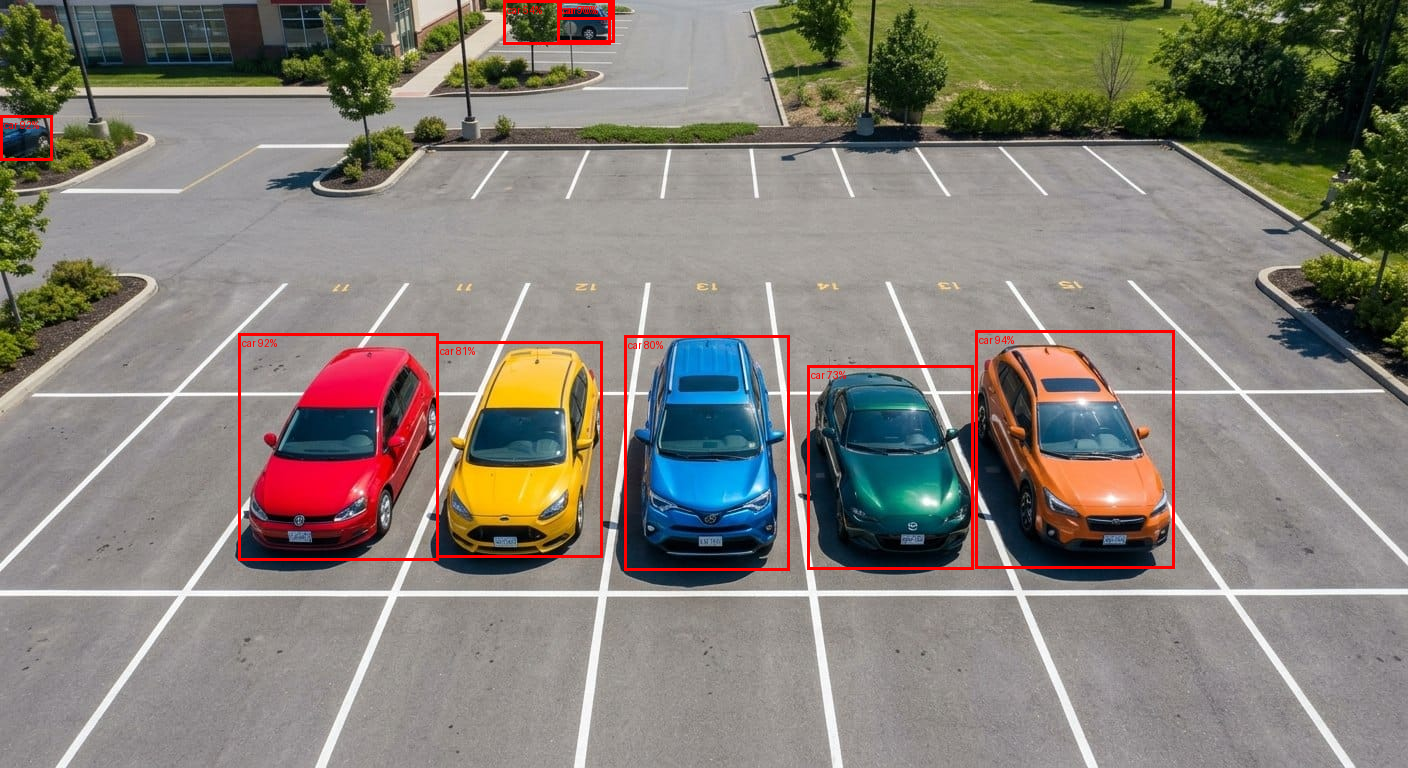

In [3]:
metricas = []
for ruta in rutas:
    with Image.open(ruta) as original:
        imagen = pil_to_tensor(ImageOps.exif_transpose(original).convert('RGB'))
    tensor = pesos.transforms()(imagen)
    with torch.inference_mode():
        inicio = time.perf_counter()
        prediccion = modelo([tensor])[0]
        tiempo_ms = (time.perf_counter() - inicio) * 1000

    seleccion = prediccion['scores'] >= 0.5
    cajas = prediccion['boxes'][seleccion]
    etiquetas = [
        f"{pesos.meta['categories'][clase]} {confianza:.0%}"
        for clase, confianza in zip(
            prediccion['labels'][seleccion].tolist(),
            prediccion['scores'][seleccion].tolist(),
        )
    ]
    anotada = draw_bounding_boxes(imagen, cajas, etiquetas, colors='red', width=3) if etiquetas else imagen
    resultado = to_pil_image(anotada)
    resultado.save(salida / ruta.name)
    assert resultado.size == (imagen.shape[2], imagen.shape[1])
    assert len(cajas) == len(etiquetas)
    metricas.append({
        'Insumo': 'Imagen 1 (Dron)' if ruta.name == 'image2.png' else 'Imagen 2 (Urbana)',
        'Archivo': ruta.name,
        'Modelo': 'Faster R-CNN',
        'Objetos detectados': len(etiquetas),
        'Tiempo de inferencia (ms)': round(tiempo_ms, 2),
        'FPS': 'N/A',
        'Observaciones': 'FP/FN no cuantificados; requiere revisión visual y anotaciones.',
    })
    print(f'{ruta.name}: {len(etiquetas)} detecciones | {tiempo_ms:.2f} ms')
    print(', '.join(etiquetas))
    display(resultado)


## 04 Tabla de métricas
`image2.png` corresponde a la vista elevada del estacionamiento (Dron en la plantilla);
`image.png`, a la escena urbana. No se dispone de video de aeropuerto.
Las imágenes no tienen anotaciones de referencia: no se calculan mAP ni totales de FP/FN.
Los tiempos se recalculan al ejecutar y dependen del equipo.


In [4]:
columnas = ['Insumo', 'Modelo', 'Objetos detectados', 'Tiempo de inferencia (ms)', 'FPS', 'Observaciones']
filas = metricas + [{
    'Insumo': 'Video Aeropuerto', 'Modelo': 'No evaluado',
    'Objetos detectados': 'N/D', 'Tiempo de inferencia (ms)': 'N/D',
    'FPS': 'N/D', 'Observaciones': 'Video no proporcionado.',
}]
with (salida / 'metricas.csv').open('w', newline='', encoding='utf-8-sig') as archivo:
    escritor = csv.DictWriter(archivo, fieldnames=['Archivo'] + columnas)
    escritor.writeheader()
    escritor.writerows(filas)
encabezado = ''.join(f'<th>{columna}</th>' for columna in columnas)
cuerpo = ''.join('<tr>' + ''.join(f'<td>{fila[columna]}</td>' for columna in columnas) + '</tr>' for fila in filas)
display(HTML(f'<table><thead><tr>{encabezado}</tr></thead><tbody>{cuerpo}</tbody></table>'))
print('Resultados guardados en:', salida.resolve())


Insumo,Modelo,Objetos detectados,Tiempo de inferencia (ms),FPS,Observaciones
Imagen 2 (Urbana),Faster R-CNN,24,10091.63,N/A,FP/FN no cuantificados; requiere revisión visual y anotaciones.
Imagen 1 (Dron),Faster R-CNN,9,1000.75,N/A,FP/FN no cuantificados; requiere revisión visual y anotaciones.
Video Aeropuerto,No evaluado,N/D,N/D,N/D,Video no proporcionado.


Resultados guardados en: /home/epadev/Documents/unap-2026/vision-computacional/06_actividad/resultados


Fuentes: [modelo de Torchvision](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.detection.fasterrcnn_mobilenet_v3_large_fpn.html),
[Faster R-CNN](https://arxiv.org/abs/1506.01497) y [YOLO](https://arxiv.org/abs/1506.02640).
